# 02. Missing Data Analysis
Analyze missing value patterns across chemical sensors and countries.

## 1. Setup
Set up analytical libraries and plot formatting.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
DATA_PATH = 'data/Dataset/Parquet/Combined Data/Combined_dataset.parquet'
OUT_DIR = 'data/GeneratedOutput/01.EDA'
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('..', '..', DATA_PATH)
    OUT_DIR = os.path.join('..', '..', OUT_DIR)
os.makedirs(OUT_DIR, exist_ok=True)
df = pd.read_parquet(DATA_PATH)
chemical_cols = [
    'Ammonia (mg/l)', 'Biochemical Oxygen Demand (mg/l)',
    'Dissolved Oxygen (mg/l)', 'Orthophosphate (mg/l)',
    'pH (ph units)', 'Temperature (cel)', 'Nitrogen (mg/l)', 'Nitrate (mg/l)'
]
print(f"Loaded dataset with {len(df):,} rows.")

Loaded dataset with 4,297,895 rows.


## 2. Missing Values per Feature
Count missing values and percentages for each chemical sensor.

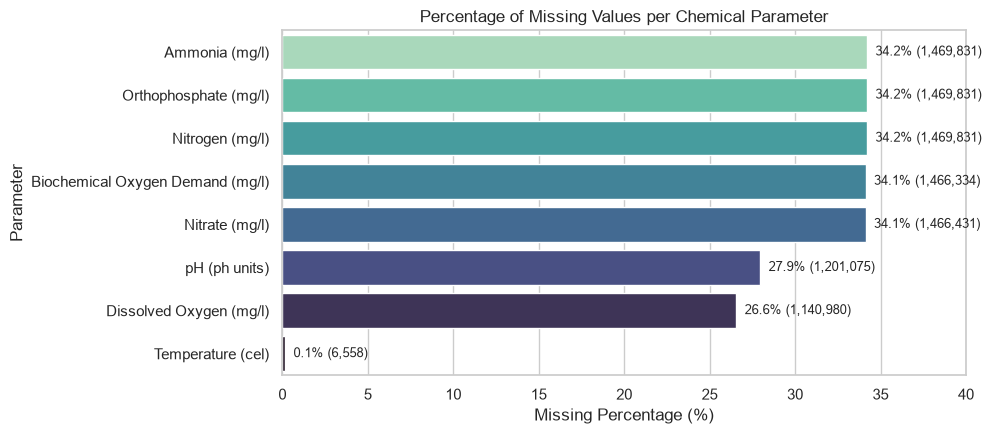

,Parameter,Missing Count,Missing %,Present Count,Present %
0,Ammonia (mg/l),1469831,34.20,2828064,65.80
1,Orthophosphate (mg/l),1469831,34.20,2828064,65.80
2,Nitrogen (mg/l),1469831,34.20,2828064,65.80
3,Biochemical Oxygen Demand (mg/l),1466334,34.12,2831561,65.88
4,Nitrate (mg/l),1466431,34.12,2831464,65.88
5,pH (ph units),1201075,27.95,3096820,72.05
6,Dissolved Oxygen (mg/l),1140980,26.55,3156915,73.45
7,Temperature (cel),6558,0.15,4291337,99.85


In [2]:
null_counts = df[chemical_cols].isnull().sum()
null_pcts = (null_counts / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'Parameter': chemical_cols,
    'Missing Count': null_counts.values,
    'Missing %': null_pcts.values,
    'Present Count': (len(df) - null_counts).values,
    'Present %': (100 - null_pcts).values
}).sort_values('Missing %', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 4.5))
ax = sns.barplot(data=missing_df, x='Missing %', y='Parameter', palette='mako_r', hue='Parameter', legend=False)
plt.title('Percentage of Missing Values per Chemical Parameter')
plt.xlabel('Missing Percentage (%)')
plt.xlim(0, 40)

for i, p in enumerate(missing_df['Missing %']):
    ax.text(p + 0.5, i, f"{p:.1f}% ({missing_df['Missing Count'].iloc[i]:,})", va='center', fontsize=9)

plt.tight_layout()
plt.show()

missing_df

## 3. Missingness Heatmap
Visualize missingness rates across countries and parameters.

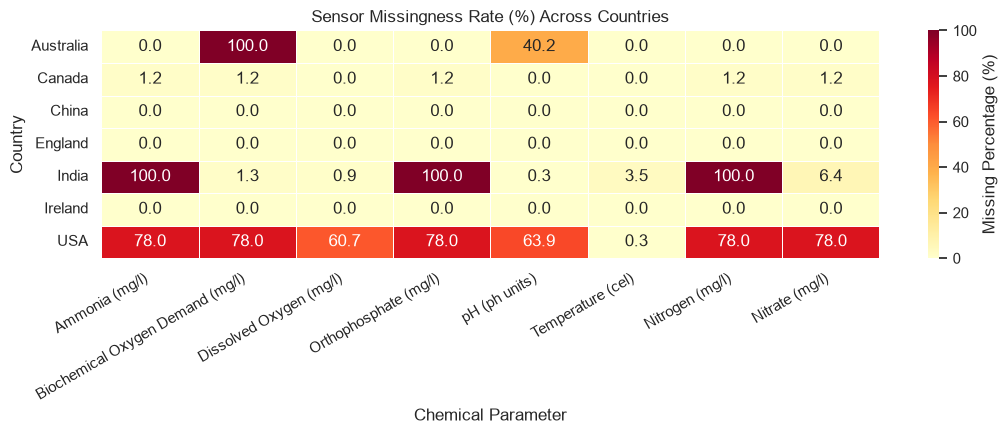

,Ammonia (mg/l),Biochemical Oxygen Demand (mg/l),Dissolved Oxygen (mg/l),Orthophosphate (mg/l),pH (ph units),Temperature (cel),Nitrogen (mg/l),Nitrate (mg/l)
Country,,,,,,,,
Australia,0.0,100.0,0.0,0.0,40.2,0.0,0.0,0.0
Canada,1.2,1.2,0.0,1.2,0.0,0.0,1.2,1.2
China,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
England,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
India,100.0,1.3,0.9,100.0,0.3,3.5,100.0,6.4
Ireland,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
USA,78.0,78.0,60.7,78.0,63.9,0.3,78.0,78.0


In [3]:
country_missing = df.groupby('Country')[chemical_cols].apply(lambda g: (g.isnull().mean() * 100).round(1))

plt.figure(figsize=(11, 4.5))
sns.heatmap(country_missing, annot=True, fmt='.1f', cmap='YlOrRd', cbar_kws={'label': 'Missing Percentage (%)'}, linewidths=0.5)
plt.title('Sensor Missingness Rate (%) Across Countries')
plt.xlabel('Chemical Parameter')
plt.ylabel('Country')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

country_missing

## 4. Sensor Co-Occurrence
Check if sensor dropouts occur independently or in groups.

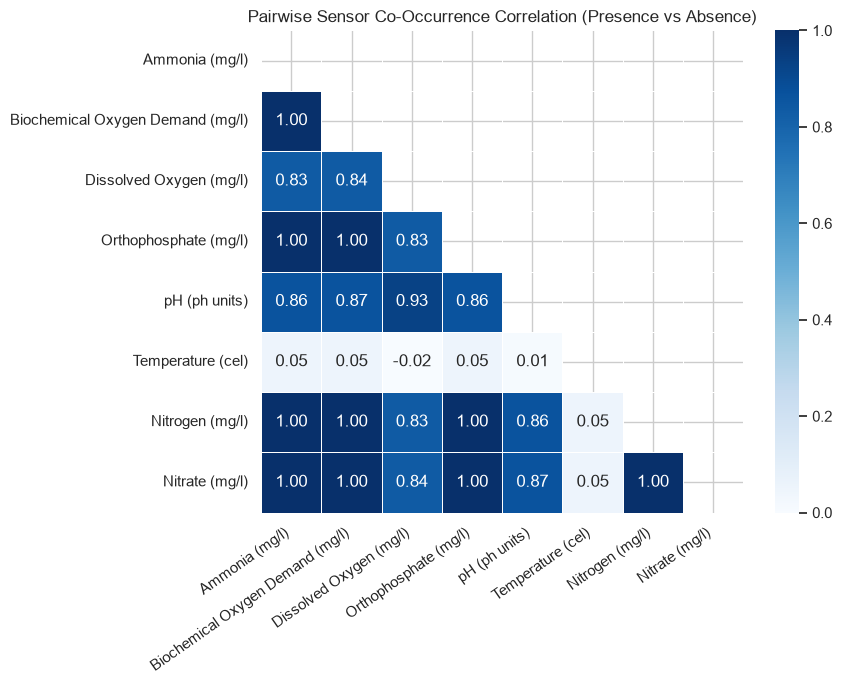

In [4]:
presence_matrix = df[chemical_cols].notnull().astype(int)
co_occurrence = presence_matrix.corr()

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(co_occurrence, dtype=bool))
sns.heatmap(co_occurrence, mask=mask, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, square=True, linewidths=0.5)
plt.title('Pairwise Sensor Co-Occurrence Correlation (Presence vs Absence)')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## 5. Completeness Analysis
Quantify complete-case availability across global records.

In [5]:
complete_mask = df[chemical_cols].notnull().all(axis=1)
complete_count = complete_mask.sum()
print(f"Total Complete-Case Records (All 8 Sensors Active): {complete_count:,} ({complete_count/len(df)*100:.2f}%)")

subset_summary = df.groupby('Country').apply(lambda g: pd.Series({
    'Total Records': len(g),
    'Complete Cases': g[chemical_cols].notnull().all(axis=1).sum(),
    'Complete %': (g[chemical_cols].notnull().all(axis=1).mean() * 100).round(2),
    'Physical Probe Only (Temp+pH+DO)': (g[['Temperature (cel)', 'pH (ph units)', 'Dissolved Oxygen (mg/l)']].notnull().all(axis=1)).sum()
})).reset_index()

subset_summary

Total Complete-Case Records (All 8 Sensors Active): 2,827,977 (65.80%)


,Country,Total Records,Complete Cases,Complete %,Physical Probe Only (Temp+pH+DO)
0,Australia,87.0,0.0,0.00,52.0
1,Canada,3995.0,3949.0,98.85,3995.0
2,China,45997.0,45997.0,100.00,45997.0
3,England,2129198.0,2129198.0,100.00,2129198.0
4,India,3633.0,0.0,0.00,3491.0
5,Ireland,235019.0,235019.0,100.00,235019.0
6,USA,1879966.0,413814.0,22.01,646830.0


## 6. Imputation Strategy
Review missingness mechanisms and imputation recommendations.

In [6]:
imputation_advice = pd.DataFrame({
    'Subset': ['England / Ireland / China', 'USA Telemetry Stations', 'India CPCB Network'],
    'Mechanism': ['Complete Data (0% Missing)', 'Missing at Random (MAR) - Telemetry vs Lab', 'Missing at Random (MAR) - Sensor absence'],
    'Downstream Strategy': [
        'Ready for direct training (2.41M rows gold benchmark)',
        'KNN / Iterative Imputation or separate probe-only head',
        'Impute BOD/DO or utilize parameter subset models'
    ]
})

out_path = os.path.join(OUT_DIR, '02_missingness_patterns.parquet')
country_missing.reset_index().to_parquet(out_path, index=False, compression='snappy')
print(f"Exported Missingness Patterns to {out_path} ({os.path.getsize(out_path)} bytes)")
imputation_advice

Exported Missingness Patterns to data/GeneratedOutput/01.EDA/02_missingness_patterns.parquet (6571 bytes)


,Subset,Mechanism,Downstream Strategy
0,England / Ireland / China,Complete Data (0% Missing),Ready for direct training (2.41M rows gold ben...
1,USA Telemetry Stations,Missing at Random (MAR) - Telemetry vs Lab,KNN / Iterative Imputation or separate probe-o...
2,India CPCB Network,Missing at Random (MAR) - Sensor absence,Impute BOD/DO or utilize parameter subset models
